In [17]:
!module load freesurfer

In [51]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from prfpy.stimulus import PRFStimulus2D
from prfpy.model import Iso2DGaussianModel
from prfpy.fit import Iso2DGaussianFitter
from prfpy.rf import gauss2D_iso_cart
import os
import yaml
import pickle
from datetime import datetime
from dag_prf_utils.utils import *
from hemi_prf.utils import *
from hemi_prf.plot_functions import *
from hemi_prf.load_functions import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [53]:
%reload_ext autoreload

In [54]:
# First we need to load the settings
prf_info = hprf_load_settings_file() # from the yaml file

In [55]:
from dag_prf_utils.fs_tools import * # Load in my tools to plot things on the freesurfer surface

ts_corr = hprf_load_run_correlation('sub-10') # Load run correlation for this subject
surf_maker = FSMaker(
    sub='sub-10',
    fs_dir='/home/fs0/pfr545/scratch/Amb_project/prf_test_full/derivatives/freesurfer/',
)

surf_maker.add_surface(
    surf_name='run_correlation',
    data=ts_corr,
    cmap='RdBu_r', 
    vmin=-1, vmax=1,  # colormap blue - negative correlation
)
surf_maker.open_fs_surface('run_correlation')


Using fs dir = /home/fs0/pfr545/scratch/Amb_project/prf_test_full/derivatives/freesurfer/
RdBu_r exists
Saving run_correlation in /home/fs0/pfr545/scratch/Amb_project/prf_test_full/derivatives/freesurfer/sub-10/surf/custom
freeview -f  lh.inflated:overlay=/home/fs0/pfr545/scratch/Amb_project/prf_test_full/derivatives/freesurfer/sub-10/surf/custom/lh.run_correlation:overlay_custom=-1.00,5,48,97,-0.89,19,75,135,-0.79,33,102,172,-0.68,52,127,185,-0.58,73,150,197,-0.47,116,178,211,-0.37,154,201,224,-0.26,189,218,234,-0.16,216,232,241,-0.05,237,242,245,0.05,248,239,234,0.16,251,224,208,0.26,250,202,177,0.37,245,172,139,0.47,232,139,110,0.58,216,101,81,0.68,198,64,62,0.79,178,25,43,0.89,141,12,37,1.00,103,0,31, rh.inflated:overlay=/home/fs0/pfr545/scratch/Amb_project/prf_test_full/derivatives/freesurfer/sub-10/surf/custom/rh.run_correlation:overlay_custom=-1.00,5,48,97,-0.89,19,75,135,-0.79,33,102,172,-0.68,52,127,185,-0.58,73,150,197,-0.47,116,178,211,-0.37,154,201,224,-0.26,189,218,234,-0.

QXcbConnection: XCB error: 11 (BadAlloc), sequence: 1254, resource id: 922, major code: 53 (CreatePixmap), minor code: 0
QXcbConnection: XCB error: 4 (BadPixmap), sequence: 1329, resource id: 39845981, major code: 54 (FreePixmap), minor code: 0
QXcbConnection: XCB error: 4 (BadPixmap), sequence: 1329, resource id: 39845981, major code: 54 (FreePixmap), minor code: 0


Number of vertices in overlay data (113735 or 113735) does not match with surface (121284).
Number of vertices in overlay data (113735 or 113735) does not match with surface (121284).


In [21]:
import scipy.io
#dm = scipy.io.loadmat('/home/fs0/pfr545/scratch/Amb_project/prf_stim/stimuli_preprocessed.mat')#['stim'].astype(np.int8)
#print(dm)

# Load the MATLAB file
dm_file = '/home/fs0/pfr545/scratch/Amb_project/prf_stim/stimuli_preprocessed.mat'  # Update with your actual file path
mat_data = scipy.io.loadmat(dm_file)
# Extract the 'stim' field and convert it to a NumPy array
stim_array = mat_data['stim'][0, 0]  # Unpack the object array
#scipy.io.savemat('stim_array.mat', {'ApFrm': stim_array})

# Confirm shape and type
print(stim_array.shape)  # Expected: (200, 200, 300)
print(type(stim_array))  # Expected: <class 'numpy.ndarray'>

(200, 200, 300)
<class 'numpy.ndarray'>


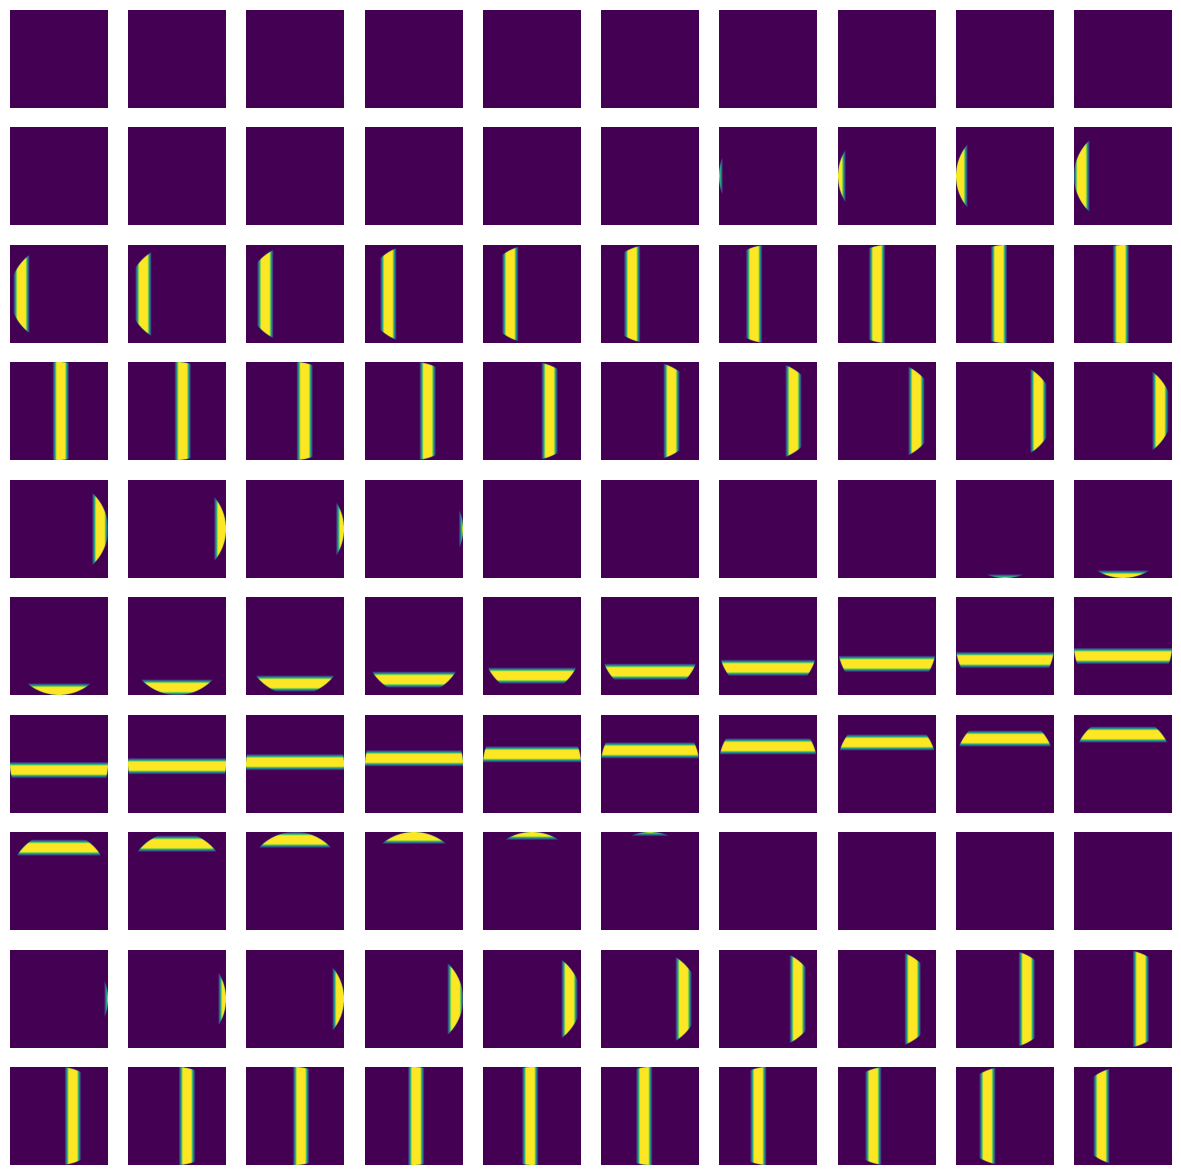

In [22]:
# If you already have the design matrix as a numpy array, you can simply load it...
dm = stim_array

# np.save('aps_hemiamap.npy', dm)
# You can see we have a binarized matrix, of a bar moving across the screen...
fig = plt.figure()
rows = 10
cols = 10
fig.set_size_inches(15,15)
for i in range(100):
    ax = fig.add_subplot(rows, cols, i+1)
    ax.imshow(dm[:,:,i], vmin=0, vmax=1)
    ax.axis('off')

In [23]:
# Now we need to enter the design matrix in a way that prfpy can read it. 
# We do this using the PRFStimulus2D object
# Information we need
# -> Screen size (height), and distance (to the eye)
# This is so that we can convert into degrees of visual angle (dov)
# -> TR: This is so that we know the time (in s), of each 'frame' / pt in the time series
# Here we have 225 time points. So total length of scan was TR * 225 (1.5*225) 
prf_stim = PRFStimulus2D(
    screen_size_cm=prf_info['screen_size_cm'],          # Distance of screen to eye
    screen_distance_cm=prf_info['screen_distance_cm'],  # height of the screen (i.e., the diameter of the stimulated region)
    design_matrix=dm,                                   # dm (npix x npix x time_points)
    TR=prf_info['TR'],                                  # TR
    task_lengths=300,
    normalize_integral_dx=True
    )
print(f'Screen size in degrees of visual angle = {prf_stim.screen_size_degrees}')

# If for some reason you do not have the original dimensions, but you do have the dov, you can use this calculator:
# https://elvers.us/perception/visualAngle/ to make up some values for screen_size and distance, which will work...


Screen size in degrees of visual angle = 14.482267733989874


In [24]:
print(dm.shape)

(200, 200, 300)


In [26]:
# Load preprocessed time series (psc), only look at first 100
derivatives_dir = '/home/fs0/pfr545/scratch/Amb_project/prf_test_H/derivatives/surface_timeseries_npy'

psc_avg_ts = hprf_load_ts_psc('sub-009', 'ses-1', ts_dir_full = derivatives_dir)
#psc_avg_ts  = psc_avg_ts[:100,:]

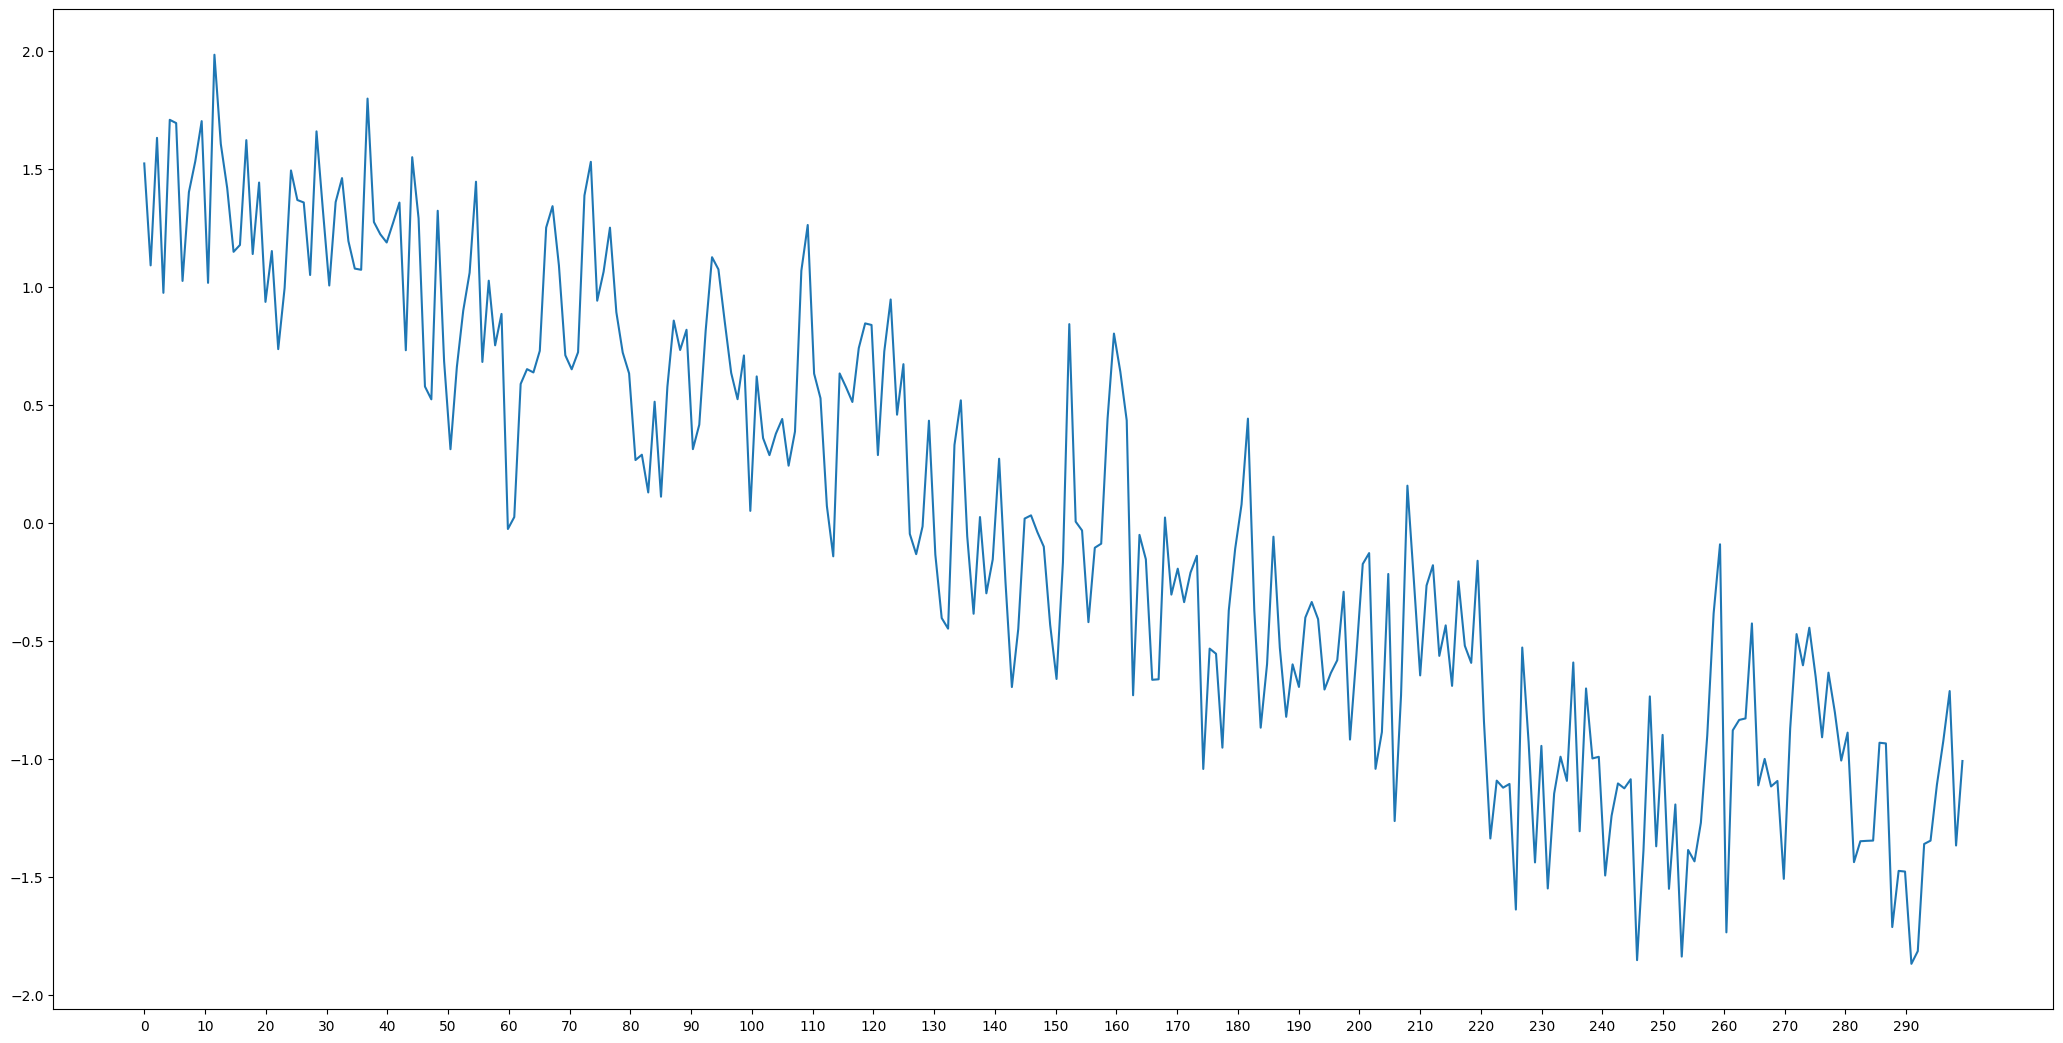

In [27]:
TR_s = prf_info['TR']
time_pts = np.arange(psc_avg_ts.shape[1]) * TR_s
i_vx = 0

fig = plt.figure()
fig.set_size_inches(20,10)
ax = fig.add_axes([0,0,1,1])
ax.plot(time_pts, psc_avg_ts[-1,:])
ax.set_xticks(np.arange(time_pts[0], time_pts[-1],10))
# add_dm_to_ts(fig, ax, dm, TR=TR_s, dx_axs=2)

from dag_prf_utils.plot_functions import *
# dag_add_dm_to_ts(fig, ax, dm, TR_in_s=TR_s, dx_axs=2)


In [28]:
'''    
    """__init__ for Iso2DGaussianModel
    constructor, sets up stimulus and hrf for this Model
    Parameters
    ----------
    stimulus : PRFStimulus2D
        Stimulus object specifying the information about the stimulus,
        and the space in which it lives.
    hrf : string, list or numpy.ndarray, optional
        HRF shape for this Model.
        Can be 'direct', which implements nothing (for eCoG or later convolution),
        a list or array of 3, which are multiplied with the three spm HRF basis functions,
        and an array already sampled on the TR by the user.
        (the default is None, which implements standard spm HRF)
    filter_predictions : boolean, optional
        whether to high-pass filter the predictions, default False
    filter_type, filter_params : see timecourse.py
    normalize_RFs : whether or not to normalize the RF volumes (generally not needed).
'''

#only does something if filtering predictions
filter_type='dc'
filter_params={"first_modes_to_remove":3,
                         "last_modes_to_remove_percent":0,
                         "window_length":50,
                         "polyorder":3,
                         "highpass":True,
                         "add_mean":True}


gg = Iso2DGaussianModel(
    stimulus=prf_stim,                                  # The stimulus we made earlier
    hrf=prf_info['hrf']['pars'],                        # These are the parameters for the HRF that we normally use at Spinoza (with 7T data). (we can fit it, this will be done later...)
    filter_predictions = prf_info['filter_predictions'],# Do you want to filter the predictions? (depends what you did to the data, try and match it... default is not to do anything)
    normalize_RFs= prf_info['normalize_RFs'],           # Normalize the volume of the RF (so that RFs w/ different sizes have the same volume. Generally not needed, as this can be solved using the beta values i.e.,amplitude)
    filter_type = filter_type, 
    filter_params=filter_params,
    hrf_basis='TDM'
    )


In [29]:


gf = Iso2DGaussianFitter(
    data=psc_avg_ts,            # time series
    model=gg,                   # model (see above)
    n_jobs=prf_info['n_jobs'],  # number of jobs to use in parallelization 
    )

In [30]:
max_eccentricity = prf_stim.screen_size_degrees/2 # It doesn't make sense to look for PRFs which are outside the stimulated region
grid_nr = prf_info['grid_nr'] #40 # # Size of the grid (i.e., number of possible PRF models). Higher number means that the grid fit will be more exact, but take longer...
eccs    = max_eccentricity * np.linspace(0.25, 1, grid_nr)**2 # Squared because of cortical magnification, more efficiently tiles the visual field...
sizes   = max_eccentricity * np.linspace(0.1, 1, grid_nr)**2  # Possible size values (i.e., sigma in gaussian model) 
polars  = np.linspace(0, 2*np.pi, grid_nr)              # Possible polar angle coordinates

#
# We can also fit the hrf in the same way (specifically the derivative)
# -> make a grid between 0-10 (see settings file)
#hrf_1_grid = np.linspace(prf_info['hrf']['deriv_bound'][0], prf_info['hrf']['deriv_bound'][1], 5)
# We generally recommend to fix the dispersion value to 0
#hrf_2_grid = np.array([0.0])
#hrf_2_grid=np.linspace(0,0,1)
# If you don't want to do any hrf fitting - set both to be NONE (uncomment below)
hrf_1_grid = None
hrf_2_grid = None


# *** Save your fitting parameters:
# We may run our analysis several times. If so we want to save the important information all together
# We will use a pickle file to do this.
prf_info['max_eccentricity']  = max_eccentricity
prf_info['eccs'] = eccs
prf_info['sizes'] = sizes
prf_info['polars'] = polars
prf_info['hrf_1_grid'] = hrf_1_grid
prf_info['hrf_2_grid'] = hrf_2_grid


In [31]:
gauss_bounds = [
    (-1.5*max_eccentricity, 1.5*max_eccentricity),          # x bound
    (-1.5*max_eccentricity, 1.5*max_eccentricity),          # y bound
    (1e-1, max_eccentricity*3),                             # prf size bounds
    (prf_info['prf_ampl'][0],prf_info['prf_ampl'][1]),      # prf amplitude
    (prf_info['bold_bsl'][0],prf_info['bold_bsl'][1]),      # bold baseline (fixed)
    (prf_info['hrf']['deriv_bound'][0], prf_info['hrf']['deriv_bound'][1]), # hrf_1 bound
    (prf_info['hrf']['disp_bound'][0], prf_info['hrf']['disp_bound'][1]), # hrf_2 bound
]
prf_info['gauss_bounds'] = gauss_bounds

In [32]:
print(gauss_bounds)

[(np.float64(-10.861700800492406), np.float64(10.861700800492406)), (np.float64(-10.861700800492406), np.float64(10.861700800492406)), (0.1, np.float64(21.72340160098481)), (0, 1000), (-3, 3), (0, 10), (0, 0)]


In [33]:
# Amplitude bounds for gauss grid fit - set [min, max]
#gauss_grid_bounds = [[prf_info['prf_ampl'][0],prf_info['prf_ampl'][1]]] 

gauss_grid_bounds = gauss_bounds
prf_info['gauss_bounds']

gf.grid_fit(
    ecc_grid=eccs,
    polar_grid=polars,
    size_grid=sizes,
    hrf_1_grid=hrf_1_grid,
    hrf_2_grid=hrf_2_grid,
    verbose=True,
    n_batches=prf_info['n_batches'],               # The grid fit is performed in parallel over n_batches of units.Batch parallelization is faster than single-unit parallelization and of sequential computing.
    fixed_grid_baseline=prf_info['fixed_grid_baseline'], # Fix the baseline? This makes sense if we have fixed the baseline in preprocessing
    grid_bounds=gauss_grid_bounds
    )
# Sometimes the fits are bad and will return NaN values. We do not want this so will remove them here:
# gf.gridsearch_params = filter_for_nans(gf.gridsearch_params)
# gf.gridsearch_r2 = filter_for_nans(gf.gridsearch_r2)

print(f'Mean rsq = {gf.gridsearch_r2.mean():.3f}')

prf_info['gauss_grid_bounds'] = gauss_grid_bounds

Each batch contains approx. 29469 voxels.


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


Mean rsq = 0.029


[Parallel(n_jobs=4)]: Done  10 out of  10 | elapsed: 25.8min finished


In [34]:
from dag_prf_utils.prfpy_functions import *
from dag_prf_utils.prfpy_ts_plotter import *
ts = TSPlotter(
    prf_params=gf.gridsearch_params,
    model='gauss', 
    prfpy_model=gg,
    real_ts=psc_avg_ts,     
    TR_in_s = TR_s,
)

prf_params.shape[-1]=8
include hrf = True
include rsq = True
real_ts and prfpy_model have different number of time points
cutting the difference


In [35]:
print(vars(gg))

{'stimulus': <prfpy.stimulus.PRFStimulus2D object at 0x7f550e784b90>, 'hrf_basis': 'TDM', 'normalize_hrf': False, 'hrf_params': array([1, 1, 0]), 'hrf': array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        1.09211381e-02, 1.74348036e-02, 1.69671865e-02, 1.41316752e-02,
        1.08961276e-02, 8.02050525e-03, 5.72391713e-03, 3.99579994e-03,
        2.74341092e-03, 1.85934642e-03, 1.24721004e-03, 8.29535788e-04,
        5.47856884e-04, 3.59637371e-04, 2.34893823e-04, 1.52711004e-04,
        9.89114855e-05, 6.38246600e-05, 4.10651921e-05, 2.63383769e-05,
        1.68529108e-05, 1.07511579e-05, 6.84449305e-06, 4.34381094e-06,
        2.74989555e-06, 1.73407970e-06, 1.08905009e-06, 6.79662507e-07,
        4.20642038e-07, 2.56872242e-07, 1.53669130e-07, 8.87246179e-08,
        4.80144368e-08, 2.25796396e-08]]), 'filter_predictions': False, 'filter_type': 'dc', 'filter_params': {'first_modes_to_remove': 3, 'last_modes_to_remove_percent': 0, 'window_length': 50, 'pol

In [36]:
np.where(gf.gridsearch_r2>0.4)[0]

array([], dtype=int64)

/home/fs0/pfr545/anaconda3/envs/prf_env/lib/python3.13/site-packages/dag_prf_utils-0.0.0-py3.13.egg/dag_prf_utils/plot_functions.py:711: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


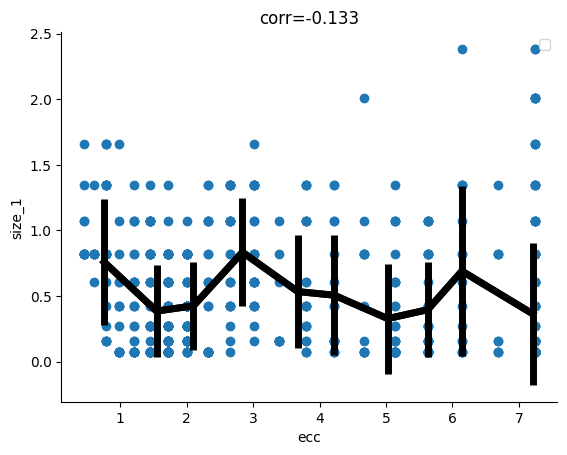

In [37]:
fig = plt.figure()
ax = plt.gca()
# ts.visual_field(ax=ax, dot_col='rsq')
ts.scatter(ax=ax, px='ecc', py='size_1', do_line=True, do_corr=True)

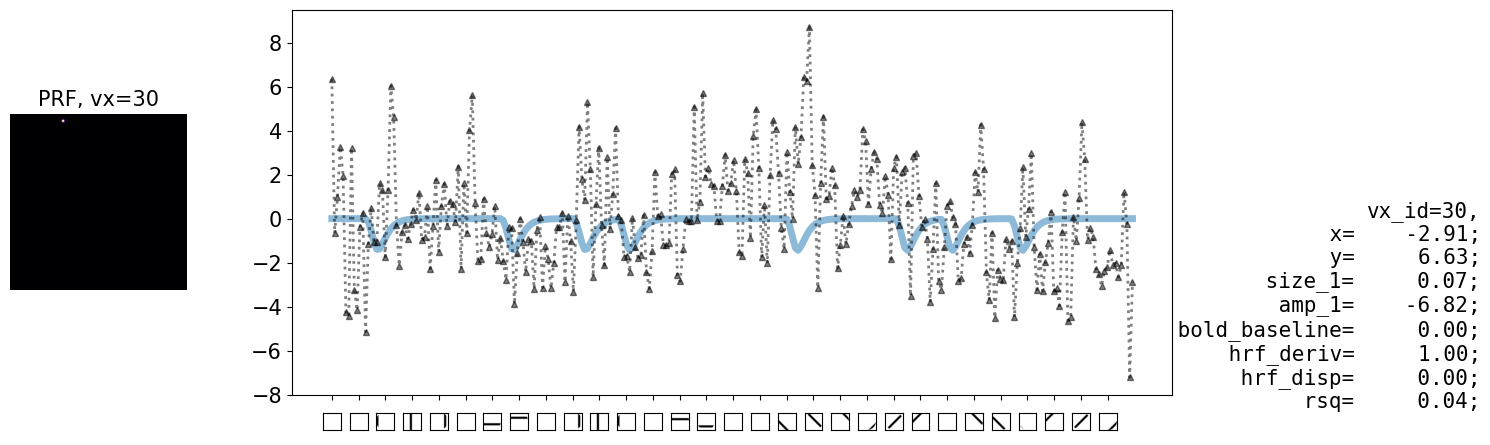

In [38]:
ts.prf_ts_plot(30)
ax = plt.gcf().get_children()[2]
# ax.set_xticks(np.arange(time_pts[0], time_pts[-1],10))
ax.set_xticks(np.arange(time_pts[0], time_pts[-1],10))
ax.set_xticklabels('')
add_dm_to_ts(plt.gcf(), ax, dm, TR=TR_s, dx_axs=2)

In [37]:
#Save grids: 
if prf_info['save_grids']:
    print('saving grids')
    grid_file = './grid_fit.pkl'
    grid_dict = {}
    grid_dict['settings'] = prf_info # Save the settings into the pickle file
    grid_dict['pars'] = gf.gridsearch_params # Save the parameters into the pickle file
    grid_dict['date'] = datetime.now().strftime('%Y-%m-%d_%H-%M') # save the date into pickle
    f = open(grid_file, "wb")
    pickle.dump(grid_dict, f)
    f.close()



saving grids


## Gaussian Iterative Fit
Now we can do the iterative fit. This takes the best fitting grid (from the above stage), and iteratively tweaks the parameters until the best fit is founds. 
This takes a bit longer than the grid fit. We also need to setup the bounds for all the parameters. 

In [43]:
gauss_bounds = [
    (-1.5*max_eccentricity, 1.5*max_eccentricity),          # x bound
    (-1.5*max_eccentricity, 1.5*max_eccentricity),          # y bound
    (1e-1, max_eccentricity*3),                             # prf size bounds
    (prf_info['prf_ampl'][0],prf_info['prf_ampl'][1]),      # prf amplitude
    (prf_info['bold_bsl'][0],prf_info['bold_bsl'][1]),      # bold baseline (fixed)
    (prf_info['hrf']['deriv_bound'][0], prf_info['hrf']['deriv_bound'][1]), # hrf_1 bound
    (prf_info['hrf']['disp_bound'][0], prf_info['hrf']['disp_bound'][1]), # hrf_2 bound
]
prf_info['gauss_bounds'] = gauss_bounds


In [45]:
print(gauss_bounds)

[(np.float64(-10.861700800492406), np.float64(10.861700800492406)), (np.float64(-10.861700800492406), np.float64(10.861700800492406)), (0.1, np.float64(21.72340160098481)), (0, 1000), (-3, 3), (0, 10), (0, 0)]


In [46]:
if prf_info['constraints']:
    # TRUE -> use trust constraint fitter:
    g_constraints = [] # Empty value for constraints. It is possible to specify something here (e.g., that the PRF cannot be very small at high eccentricities...)
else:
    # FALSE -> use BGFS fitter (faster, but stays closer to the grid)
    g_constraints = None # uses l-BFGS (which is faster)


gf.iterative_fit(
    rsq_threshold=prf_info['rsq_threshold'],    # Minimum variance explained. Puts a lower bound on the quality of PRF fits. Any fits worse than this are thrown away...     
    verbose=True,
    bounds=gauss_bounds,       # Bounds (on parameters)
    constraints=g_constraints, # Constraints
    xtol=float(prf_info['xtol']),     # float, passed to fitting routine numerical tolerance on x
    ftol=float(prf_info['ftol']),     # float, passed to fitting routine numerical tolerance on function
    )               
# Xtol and Ftol determine when the fitter stops trying to improve the fit. Set to higher values to to terminate sooner and speed up the fitting
# Sometimes the fits are bad and will return NaN values. We do not want this so will remove them here:
# gf.iterative_search_params = filter_for_nans(gf.gridsearch_params)


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


Performing bounded, unconstrained minimization (L-BFGS-B).Performing bounded, unconstrained minimization (L-BFGS-B).
Performing bounded, unconstrained minimization (L-BFGS-B).

Performing bounded, unconstrained minimization (L-BFGS-B).
Performing bounded, unconstrained minimization (L-BFGS-B).
Performing bounded, unconstrained minimization (L-BFGS-B).
Performing bounded, unconstrained minimization (L-BFGS-B).
Performing bounded, unconstrained minimization (L-BFGS-B).


ValueError: operands could not be broadcast together with shapes (286,) (1,300) 

In [ ]:
# The parameters are stored as a np.ndarray with units x parameters
# gf.iterative_search_params[:,0] -> x position of prf
# gf.iterative_search_params[:,1] -> y position of prf
# gf.iterative_search_params[:,2] -> size of prf
# gf.iterative_search_params[:,3] -> amplitude of prf
# gf.iterative_search_params[:,4] -> baseline of prf
# gf.iterative_search_params[:,5] -> rsq of prf


# Plot the x,y location of all the PRFs, which have a good fit...
good_fit_idx = gf.iterative_search_params[:, -1] > 0.1
good_fit_x = gf.iterative_search_params[good_fit_idx, 0]
good_fit_y = gf.iterative_search_params[good_fit_idx, 1]

plt.scatter(good_fit_x, good_fit_y)
plt.xlim(-max_eccentricity,max_eccentricity)
plt.ylim(-max_eccentricity,max_eccentricity)

In [ ]:
# We can now create the predicted timeseries, and compare these with the data
prf_params = gf.iterative_search_params
pred_tc = gg.return_prediction(
    mu_x = prf_params[:,0], # x position
    mu_y = prf_params[:,1], # y position
    size = prf_params[:,2], # prf size
    beta = prf_params[:,3], # prf amplitude
    baseline = prf_params[:,4], # prf baseline (set to 0)
    hrf_1 = prf_params[:,5],
    hrf_2 = prf_params[:,6],
)

# Sometimes the fits are bad and will return NaN values. We do not want this so will remove them here:
pred_tc = filter_for_nans(pred_tc)

In [ ]:
# Now to save everything in a nice convenient pickle file
print('saving iterative search params')
iter_file = './iter_fit.pkl'
iter_dict = {}
iter_dict['settings'] = prf_info # Save the settings into the pickle file
iter_dict['pars'] = gf.iterative_search_params # Save the parameters into the pickle file
iter_dict['preds'] = pred_tc # Save the predicted time series into the pickle file
iter_dict['date'] = datetime.now().strftime('%Y-%m-%d_%H-%M') # save the date into pickle
f = open(iter_file, "wb")
pickle.dump(iter_dict, f)
f.close()
